# Lab 3: Image Classification

Image classification is a computer vision technique to categorize an image based using its visual content. The approches include:  

1. Classiscal approach: task-based manual feature extarction and perform classification using machine leaning classifiers like support vector machine, random forest etc.  

2. Deep learning approach: Training a convolutional neural networks (CNN) models like Resnet, YOLO, ViT etc.

## Traffic Light Color Detection

In this lab we will do traffic light color detection which is crucial for autonomous driving. Recognizing traffic light colors—red, yellow, and green—is essential for making real-time decisions such as stopping, slowing down, or proceeding.


In this lab, we will do trafiic light color detection using the dataset curated for Udacity course on *Intro To Self Driving Cars*. 

<img title="a title" alt="Alt text" src="traffic_light_color_sample.png" width="200" height="300">


*All images come from MIT self-driving car course and are licensed under a Creative Commons Attribution-ShareAlike 4.0 International License.*

### Tasks
Implement and test two classifiers:
1. A simple classical that uses classic computer vision techniques.
2. Training a CNN like ResNet, YOLO, ViT etc of your choice using Pytorch.

### Objective: 
1. Get classification accuracy of >90% on test dataset.
2. Avoid incorrect classification of Red light as Green light

### Outcome
1. Classical Approach:
    - Short description of the approach used for detecting traffic light color.
    - How did you decide the thresholds if done manually? How did you create the feature vector if using SVM or random forest classifiers?
    - Function to detect traffic light color.
    ```
    def trafficColorDetection(image:np.ndarray)->str:
        '''
        function to detect traffic light color.
        
        image: color image
        ___
        color: string of the detected color: 'Red', 'Green', 'Yellow'
        '''
        ...
    ```
    - Confusion matrix and the accuracy on the test dataset.
    - An overview of the results. Do you think the accuracy you get is satisfactory. Any suggstions to improve the results further.


2. Deep Learning Approach:
    - Short description related of the approch used for training the deep learning model.
        - CNN model used
        - Image augmentations
        - Image size used for training and testing. Are they different?
        - Selection of optimizer, number of epochs, batch size
        - Loss function
        
    - Show the training plots (training loss, testing loss, testing accuracy). Do you think the training was good just looking at the plots.
    - Confusion matrix and the accuracy on the test dataset using the best trained model.
    - An overview of the results. Do you think the accuracy you get is satisfactory. Any suggstions to improve the results further.

### Useful Modules

Data loading: *[torchvision.datasets.ImageFolder](https://pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)*

Classification Report: *[sklearn.metrics.classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)*

Confusion Metrics: *[sklearn.metrics.confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)*

Deep Learning Model: *[torch.hub.load](https://pytorch.org/vision/main/models.html)*

Image Augmentations: *[torchvision.transforms.v2](https://pytorch.org/vision/main/transforms.html)*


# 3.1 Classical Approach

**Add method description Here**

### Steps:
1. Create the fucntion *trafficColorDetection*.
2. Load dataset and fine tune model on train dataset only.
3. Generate accuracy report and visualize confusion matrix.

In [1]:
from sklearn import svm
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
import numpy as np
import cv2

def extract_color_features(image: np.ndarray) -> np.ndarray:
    '''
    Function to extract color-related features (like mean HSV values)
    from the image to use as input for the classifier.
    '''
    # Convert the image to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    
    # Compute the mean HSV value for the image
    mean_hue = np.mean(hsv[:, :, 0])
    mean_saturation = np.mean(hsv[:, :, 1])
    mean_value = np.mean(hsv[:, :, 2])
    
    return np.array([mean_hue, mean_saturation, mean_value])

# Load and preprocess the dataset (images and labels)
images = [cv2.imread(f'path_to_image{i}.jpg') for i in range(10)]  # Replace with actual image paths
labels = ['Red', 'Green', 'Yellow', 'Red', 'Green', 'Yellow', 'Red']  # Labels for images

# Extract features for each image
X = [extract_color_features(img) for img in images]

# Encode labels to numerical format
label_dict = {'Red': 0, 'Green': 1, 'Yellow': 2}
y = [label_dict[label] for label in labels]

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train the SVM classifier
clf = svm.SVC(kernel='linear')  # You can try different kernels (linear, rbf, etc.)
clf.fit(X_train, y_train)

# Predict on test data
y_pred = clf.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)



import cv2
import numpy as np

def trafficColorDetection(image:np.ndarray)->str:
    '''
    function to detect traffic light color.
    
    image: color image
    ___
    color: string of the detected color: 'Red', 'Green', 'Yellow'
    '''
    ...



def trafficColorDetection(image:np.ndarray) -> str:
    """
    Detects traffic light color using classical image processing.
    
    Parameters:
        image (np.ndarray): Input image in BGR format.

    Returns:
        str: Detected color ('Red', 'Yellow', or 'Green').
    """
    # Convert image to HSV color space
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    
    # Define HSV ranges for red, yellow, and green
    red_lower = np.array([0, 100, 100])
    red_upper = np.array([10, 255, 255])
    green_lower = np.array([40, 50, 50])
    green_upper = np.array([90, 255, 255])
    yellow_lower = np.array([20, 100, 100])
    yellow_upper = np.array([30, 255, 255])

    # Create masks
    red_mask = cv2.inRange(hsv, red_lower, red_upper)
    green_mask = cv2.inRange(hsv, green_lower, green_upper)
    yellow_mask = cv2.inRange(hsv, yellow_lower, yellow_upper)

    # Count pixels in each mask
    red_count = np.sum(red_mask)
    green_count = np.sum(green_mask)
    yellow_count = np.sum(yellow_mask)

    # Determine the color with the highest pixel count
    if red_count > green_count and red_count > yellow_count:
        return "Red"
    elif green_count > yellow_count:
        return "Green"
    else:
        return "Yellow"


error: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:196: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


In [21]:
# Data Loading: Load train and test images seperately
import os
from matplotlib import pyplot as plt

def loadDataset(dataPath):
    """
    Loads the traffic light dataset.

    Parameters:
        data_path (str): Path to the dataset folder, structured as:
                         - data_path/
                             - Red/
                             - Yellow/
                             - Green/

    Returns:
        list: List of image arrays.
        list: List of corresponding labels.
    """
    images = []
    labels = []

    # Iterate through subfolders
    for label in ["Red", "Yellow", "Green"]:
        folderPath = os.path.join(dataPath, label)
        for filename in os.listdir(folderPath):
            imgPath = os.path.join(folderPath, filename)
            img = cv2.imread(imgPath)
            images.append(img)
            labels.append(label)

    return images, labels

trainingImages, trainingLabels = loadDataset("Traffic_Light_Images\\training")

test = loadDataset("Traffic_Light_Images\\test")

# Fine tuning parameters/threshold depending for classical approach using train dataset

# Task 3.1: Classical Approach 1 - Dataset Loading and Parameter Fine-Tuning
def segment_traffic_light(image, thresholds):
    """
    Segments the traffic light in an image based on HSV thresholds.

    Parameters:
        image (numpy array): Input BGR image.
        thresholds (dict): HSV thresholds for each traffic light color.

    Returns:
        str: Predicted label ("Red", "Yellow", "Green").
    """
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    for label, threshold in thresholds.items():
        mask = cv2.inRange(hsv, threshold["lower"], threshold["upper"])
        # Apply morphological operations
        kernel = np.ones((5, 5), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        # Check if significant region is detected
        if cv2.countNonZero(mask) > 100:  # Adjust threshold as needed
            return label
    return "None"

def fine_tune_parameters(images, labels):
    """
    Fine-tunes HSV thresholds using the training dataset.

    Parameters:
        images (list): List of training images.
        labels (list): Ground truth labels.

    Returns:
        dict: Fine-tuned HSV thresholds.
    """
    # Initial HSV thresholds
    thresholds = {
        "Red": {"lower": np.array([0, 100, 100]), "upper": np.array([10, 255, 255])},
        "Yellow": {"lower": np.array([20, 100, 100]), "upper": np.array([30, 255, 255])},
        "Green": {"lower": np.array([40, 50, 50]), "upper": np.array([90, 255, 255])},
    }

    best_thresholds = thresholds.copy()
    best_accuracy = 0

    for _ in range(5):  # Number of iterations for fine-tuning
        predictions = []
        for i, img in enumerate(images):
            predicted_label = segment_traffic_light(img, thresholds)
            predictions.append(predicted_label)
        
        # Calculate accuracy
        true_labels = labels
        accuracy = np.mean(np.array(predictions) == np.array(true_labels))
        print(f"Iteration Accuracy: {accuracy:.2f}")

        # Adjust thresholds dynamically based on errors
        for label in thresholds:
            errors = [i for i, (pred, true) in enumerate(zip(predictions, true_labels)) if pred != true and true == label]
            if errors:
                # Example of tuning strategy: Expand thresholds slightly for missed colors
                thresholds[label]["lower"][0] = max(0, thresholds[label]["lower"][0] - 2)
                thresholds[label]["upper"][0] = min(180, thresholds[label]["upper"][0] + 2)

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_thresholds = thresholds.copy()

    return best_thresholds

# Fine-tune thresholds using the training dataset
fine_tuned_thresholds = fine_tune_parameters(trainingImages, trainingLabels)

print("Fine-tuned thresholds:")
print(fine_tuned_thresholds)


Iteration Accuracy: 0.17
Iteration Accuracy: 0.25
Iteration Accuracy: 0.28
Iteration Accuracy: 0.30
Iteration Accuracy: 0.31
Iteration Accuracy: 0.32
Iteration Accuracy: 0.33
Iteration Accuracy: 0.33
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.34
Iteration Accuracy: 0.32
Iteration Accuracy: 0.26
Iteration Accuracy: 0.22
Iteration Accuracy: 0.20
Iteration Accuracy: 0.19
Iteration Accuracy: 0.19
Iteration Accuracy: 0.18
Iteration Accuracy: 0.18
Iteration Accuracy: 0.18
Iteration Accuracy: 0.18
Iteration Accuracy: 0.18


In [18]:
# Traffic signal detection on the test dataset after finalizing the parameters/thresholds


# Generate Accuracy report on test dataset
from sklearn.metrics import classification_report

def evaluate_model(images, labels, thresholds):
    """
    Evaluates the classical segmentation model using fine-tuned thresholds.

    Parameters:
        images (list): List of test images.
        labels (list): Ground truth labels.
        thresholds (dict): Fine-tuned HSV thresholds.

    Returns:
        None: Prints classification report.
    """
    predictions = [segment_traffic_light(img, thresholds) for img in images]
    print("Classification Report:")
    print(classification_report(labels, predictions))

# Evaluate the model using the fine-tuned thresholds
evaluate_model(trainingImages, trainingLabels, fine_tuned_thresholds)


Classification Report:
              precision    recall  f1-score   support

       Green       0.95      0.75      0.84       429
        None       0.00      0.00      0.00         0
         Red       0.85      0.08      0.14       723
      Yellow       1.00      0.11      0.21        35

    accuracy                           0.32      1187
   macro avg       0.70      0.24      0.30      1187
weighted avg       0.89      0.32      0.40      1187



c:\Users\zsven\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\zsven\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\zsven\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capita

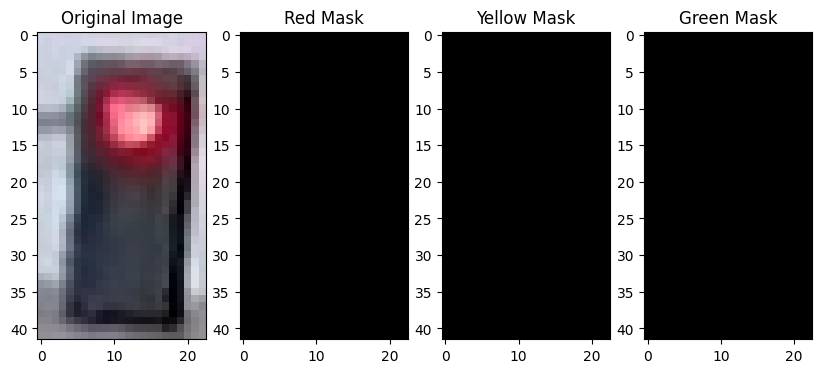

In [19]:
# Visualize confusion matrix on test dataset

def visualize_segmentation(image, thresholds):
    """
    Visualizes the segmented mask for a given image.

    Parameters:
        image (numpy array): Input BGR image.
        thresholds (dict): HSV thresholds for segmentation.

    Returns:
        None: Displays original image and segmentation results.
    """
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    masks = {label: cv2.inRange(hsv, th["lower"], th["upper"]) for label, th in thresholds.items()}

    plt.figure(figsize=(10, 5))
    plt.subplot(1, len(masks) + 1, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")

    for i, (label, mask) in enumerate(masks.items()):
        plt.subplot(1, len(masks) + 1, i + 2)
        plt.imshow(mask, cmap="gray")
        plt.title(f"{label} Mask")

    plt.show()

# Visualize segmentation on a sample image
sample_image = trainingImages[0]  # Replace with an image from the dataset
visualize_segmentation(sample_image, fine_tuned_thresholds)


<span style="color:Red">Q1</span>. Do you think the accuracy you get is satisfactory. 

<span style="color:Red">Q2</span>. Any suggstions to improve the results further (Please don't put use deep learning methods).

# 3.2 Deep Learning Approach
**Use Pytorch 2.2 or above**

### Steps:
1. Go over the list of classification models, training and testing image augmentations, optimizer, and loss fucntions avilable in Pytorch. Select the ones you want to try.
2. Load dataset and create dataloaders.
3. Train the model. Decide how to select the best model (high test accuracy, low loss or something)
4. Generate accuracy report and visualize confusion matrix on test dataset.

In [20]:
import torch
import torchvision
from tqdm.auto import tqdm
from torchvision import transforms
from logger import LOGGER, GenericLogger

ModuleNotFoundError: No module named 'torch'

In [ ]:
# Device cpu or cuda
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# Logger
logger = GenericLogger(save_dir="/path/to/save/model/", console_logger=LOGGER)

In [ ]:
# Select Model and change the 
model = torch.hub.load()
model.to(device)
print(model)

#change the last layer so the output size is number of classes needed

<span style="color:Red">Q3</span>. Explain the choice of augmentations, optimizer and loss function used.

In [ ]:
# Select batch size
bs = 4
image_size = () #=(h, w)


# create the train and test augmentations
train_augmentation = transforms.Compose([
    
])

test_augmentation = transforms.Compose([
    
])

# create train and test dataloader
# images should be normalized
train_dataset = ...
test_dataset = ...

train_dataloader = ...
test_dataloader = ...

In [ ]:
# Visualize the images from dataloader

In [ ]:
# assign class name to the model
model.names = train_dataloader.dataset.classes  # attach class names

In [ ]:
# Select Optimizer
# need to decide the leraning rate ad other parameters
optimizer = ...

# Select Loss function
criterion = ... # for multi-class classification

best_fitness = 0.0

In [ ]:
# Number of epochs
epochs = ...
t0 = time.time()


In [ ]:
for epoch in range(epochs):  # loop over the dataset multiple times
    tloss, vloss, fitness = 0.0, 0.0, 0.0  # train loss, val loss, fitness
    model.train() #setting model weight for training or activating gradient calculation

    pbar = tqdm(enumerate(train_dataloader), total=len(train_dataloader), bar_format=TQDM_BAR_FORMAT)
    for i, (images, labels) in pbar:  # progress bar
        images, labels = images.to(device, non_blocking=True), labels.to(device)

        # Forward
        loss = criterion(model(images), labels)

        # Backward
        loss.backward()

        # Optimize
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)  # clip gradients
        optimizer.step()
        optimizer.zero_grad()
        
        # Print
        tloss = (tloss * i + loss.item()) / (i + 1)  # update mean losses
        mem = '%.3gG' % (torch.cuda.memory_reserved() / 1E9 if torch.cuda.is_available() else 0)  # (GB)
        pbar.desc = f"{f'{epoch + 1}/{epochs}':>10}{mem:>10}{tloss:>12.3g}" + ' ' * 36

    # Test
    model.eval()
    with torch.no_grad():
        vpred, vtargets, vloss, dt = [], [], 0
        n = len(testloader)
        for images, labels in bar:
            images, labels = images.to(device, non_blocking=True), labels.to(device)
            y = model(images)
            vpred.append(y.argsort(1, descending=True)[:, 0]) # top1
            vtargets.append(labels)
            if criterion:
                vloss += criterion(y, labels)

            vloss /= n
            pred, targets = torch.cat(vpred), torch.cat(vtargets)
            correct = (vtargets[:, None] == vpred).float()[:,0]
            top1 = acc.mean().value()
        
            if pbar:
                pbar.desc = f'{pbar.desc[:-36]}{vloss:>12.3g}{top1:>12.3g}'

    fitness = top1  # define fitness as top1 accuracy


    # Log metrics
    # Best fitness
    if fitness > best_fitness:
        best_fitness = fitness

    # Log
    metrics = {
        'train/loss': tloss,
        'test/loss': vloss,
        'metrics/accuracy_top1': top1,
        'lr/0': optimizer.param_groups[0]['lr']}  # learning rate
    logger.log_metrics(metrics, epoch)

    # Save model
    final_epoch = epoch + 1 == epochs
    if True or final_epoch:
        ckpt = {
            'epoch': epoch,
            'best_fitness': best_fitness,
            'model': deepcopy(de_parallel(model)).half(), #model.half()
            'date': datetime.now().isoformat()}

        # Save last, best and delete
        torch.save(ckpt, last)
        if best_fitness == fitness:
            torch.save(ckpt, best)
        del ckpt

<span style="color:Red">Q4</span>. Explain the training and test plots. What criteria is used for selecting the best model?

Note: Put the training plots in the notebook.